In [20]:
import numpy as np
import matplotlib.pyplot as plt
import requests

import hapkeRTM
import loadData

In [35]:
# Example data URL
files = ["https://pds-geosciences.wustl.edu/speclib/urn-nasa-pds-relab/data_reflectance/bdr2/c1lr17.tab",
         "https://pds-geosciences.wustl.edu/speclib/urn-nasa-pds-relab/data_reflectance/bdr2/c1lr32.tab",
         "https://pds-geosciences.wustl.edu/speclib/urn-nasa-pds-relab/data_reflectance/bdr3/c1lr169.tab"]

# List of file names to download
file_names = ["c1lr17.tab", "c1lr32.tab", "c1lr169.tab"]

# Download each file
for i in range(len(files)):
    file_url = files[i]
    file_path = file_names[i]  # Save in the current directory

    response = requests.get(file_url)
    if response.status_code == 200:
        with open(file_path, "wb") as file:
            file.write(response.content)
        print(f"Downloaded: {file_names[i]}")
    else:
        print(f"Error {file_names[i]}: {response.status_code}")

Downloaded: c1lr17.tab
Downloaded: c1lr32.tab
Downloaded: c1lr169.tab


### Main: Depth correction example

In [22]:
# load wavelength and reflectance for spaceweathered and mixture
w_sw, r_sw = loadData.importspeclib( "c1lr17.tab" ) #79221 
w_mix, r_mix = loadData.importspeclib( "c1lr32.tab" ) #12030

# convert reflectance to single scattering albedo
w_sw, ssa_sw = hapkeRTM.HapkeRTM(emergence_angle=0, incidence_angle=30, phase_angle=30, wavelengths=w_sw, reflectances=r_sw).ref2ssa()
w_mix, ssa_mix = hapkeRTM.HapkeRTM(emergence_angle=0, incidence_angle=30, phase_angle=30, wavelengths=w_mix, reflectances=r_mix).ref2ssa()

# apply depth correction
w_dc, ssa_dc = hapkeRTM.HapkeCorrection(wavelengths = w_sw, ssa_mix = ssa_mix, ssa_sw = ssa_sw).ssa_dc()

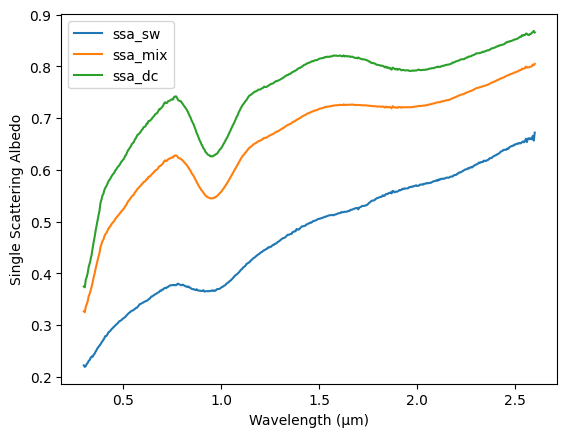

In [23]:
plt.plot(w_sw,ssa_sw,label="ssa_sw")
plt.plot(w_mix,ssa_mix,label="ssa_mix")
plt.plot(w_dc,ssa_dc,label="ssa_dc")
plt.xlabel('Wavelength (µm)')
plt.ylabel('Single Scattering Albedo')
plt.legend()

### Appendix C: Derivation of single scattering albedo using the Hapke radiative transfer model

In [29]:
w, r = loadData.importspeclib( "c1lr169.tab" ) # olivine reflectance

hapke_model = hapkeRTM.HapkeRTM(
    emergence_angle=0,
    incidence_angle=30,
    phase_angle=30,
    wavelengths=w,
    reflectances=r
)

w, ssa = hapke_model.ref2ssa()

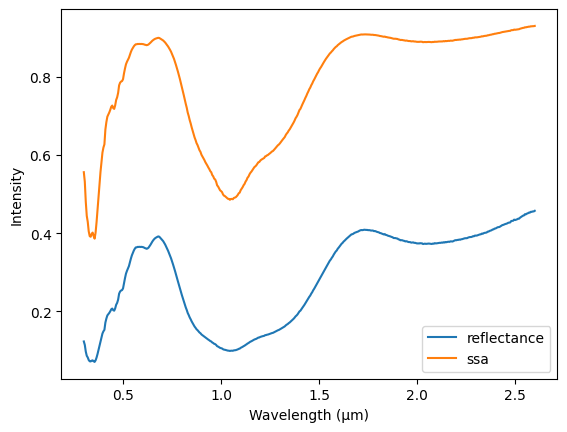

In [30]:
plt.plot(w,r,label="reflectance")
plt.plot(w,ssa,label="ssa")
plt.xlabel('Wavelength (µm)')
plt.ylabel('Intensity')
plt.legend()

### Appendix D: Calculation of mineral endmember's imaginary refractive index (k) from reflectance data using bisection method.

In [33]:
w, r = loadData.importspeclib( "c1lr169.tab" ) # olivine reflectance

hapke_model = hapkeRTM.HapkeRTM(
    emergence_angle=0,
    incidence_angle=30,
    phase_angle=30,
    wavelengths=w,
    reflectances=r
)

w, k = hapke_model.k(tol=1e-15, st=20, ed=460, n=1.83, D=80)

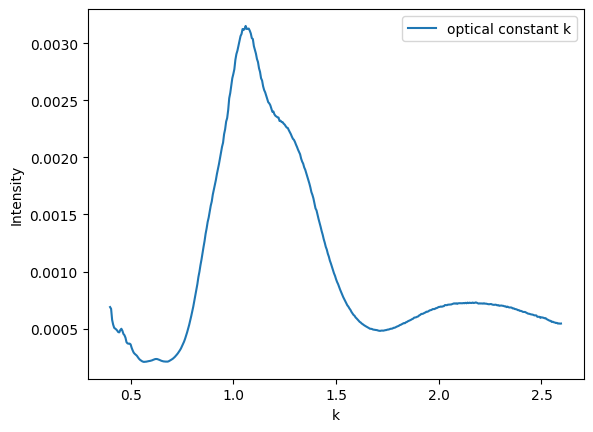

In [34]:
plt.plot(w,k,label="optical constant k")
plt.xlabel('k')
plt.ylabel('Intensity')
plt.legend()